In [611]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [612]:
data_path=pd.read_csv("kmeans_ecommerce_75000.csv")
df=pd.DataFrame(data_path)
print(df.head())

   customer_id   age  annual_income_inr  orders_last_12_months  \
0       126838  47.0          3379341.0                     29   
1       102593  56.0          1549816.0                      9   
2       118360  40.0           549247.0                      1   
3       173293  53.0           401658.0                      1   
4       160128  30.0           479497.0                     12   

   average_order_value_inr  total_spend_last_12_months_inr  \
0                  1489.03                        43181.87   
1                  3771.52                        33943.68   
2                   403.98                          403.98   
3                   342.76                          342.76   
4                  1590.29                        19083.48   

   days_since_last_purchase  days_since_registration  \
0                         6                      778   
1                         8                     1052   
2                        49                     1119   
3     

In [613]:
print(df.shape)

(75000, 10)


In [614]:
print(df.describe())

         customer_id           age  annual_income_inr  orders_last_12_months  \
count   75000.000000  74800.000000       7.480000e+04           75000.000000   
mean   137453.327133     46.543088       8.749728e+05              14.908160   
std     21622.547613     16.697442       5.935170e+05              12.102525   
min    100001.000000     18.000000       7.698700e+04               1.000000   
25%    118727.750000     32.000000       4.277840e+05               5.000000   
50%    137457.500000     47.000000       7.202575e+05              10.000000   
75%    156179.250000     61.000000       1.164812e+06              22.000000   
max    174900.000000     75.000000       7.399867e+06              60.000000   

       average_order_value_inr  total_spend_last_12_months_inr  \
count             75000.000000                    7.500000e+04   
mean               1562.391731                    2.524433e+04   
std                1093.305202                    2.826878e+04   
min            

In [615]:
df=df.dropna()
print(df.shape)

(74204, 10)


In [616]:
df = df.drop_duplicates()
print(df.shape)

(74104, 10)


In [617]:
pc_unique=df["preferred_channel"].unique()
print(pc_unique)

<ArrowStringArray>
['App', 'Store', 'Website']
Length: 3, dtype: str


In [618]:
X=df[["annual_income_inr",
    "orders_last_12_months",
    "average_order_value_inr",
    "total_spend_last_12_months_inr",
    "discount_order_percentage"]]

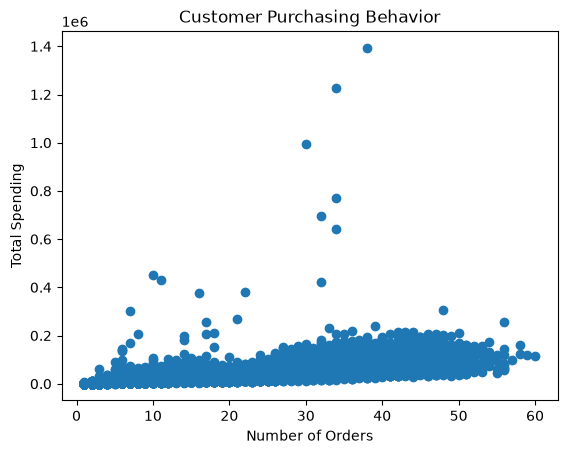

In [619]:
plt.scatter(
    df["orders_last_12_months"],
    df["total_spend_last_12_months_inr"]
)

plt.xlabel("Number of Orders")
plt.ylabel("Total Spending")
plt.title("Customer Purchasing Behavior")
plt.show()

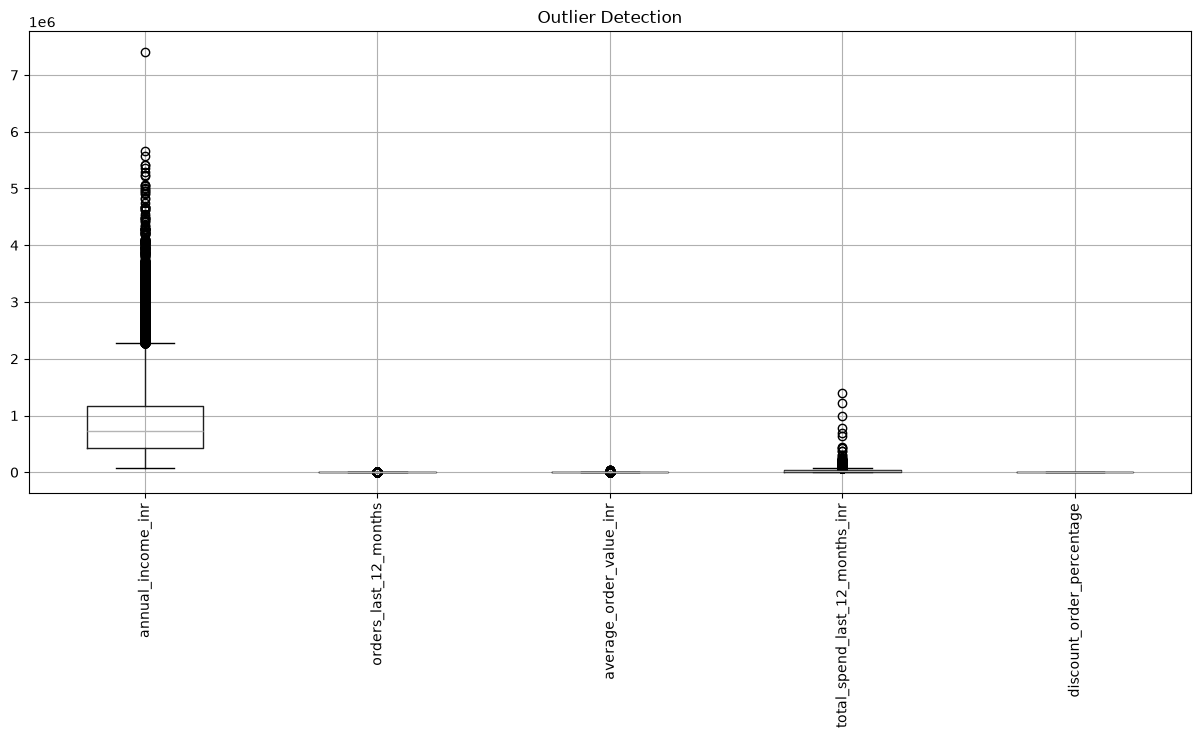

In [620]:
plt.figure(figsize=(15, 6))
X.boxplot()
plt.xticks(rotation=90)
plt.title("Outlier Detection")
plt.show()

In [621]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (X < lower_bound) | (X > upper_bound)

print(outliers.sum())

annual_income_inr                 2298
orders_last_12_months              323
average_order_value_inr           1684
total_spend_last_12_months_inr    4406
discount_order_percentage            0
dtype: int64


In [622]:
X = X.clip(
    lower=lower_bound,
    upper=upper_bound,
    axis=1
)

In [623]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X)

In [624]:
model=KMeans(
    n_clusters=3,
    random_state=42,
    n_init=50,
    max_iter=500
)

In [625]:
model.fit(X_train_scaled)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",50
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[[ 1.

In [626]:
print(model.n_clusters)
print(np.unique(model.labels_))

3
[0 1 2]


In [627]:
centers=model.cluster_centers_
print(centers)

[[ 1.02580105 -0.08470876  0.97927628  0.14481144 -0.46607415]
 [ 0.35499038  1.38149196  0.46880162  1.38853593 -0.23022335]
 [-0.29187594 -0.00774641 -0.32036652 -0.27365962  0.28739245]]


In [628]:
df["clusters"] = model.labels_

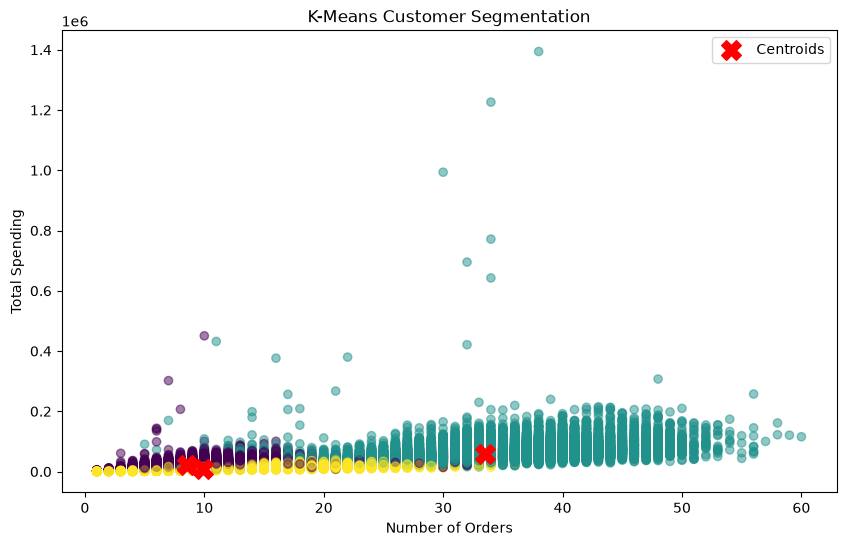

Number of clusters: 3
Number of centroids: 3


In [629]:
centers = scaler.inverse_transform(model.cluster_centers_)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["orders_last_12_months"],
    df["total_spend_last_12_months_inr"],
    c=df["clusters"],
    cmap="viridis",
    alpha=0.5
)

plt.scatter(
    centers[:, X.columns.get_loc("orders_last_12_months")],
    centers[:, X.columns.get_loc("total_spend_last_12_months_inr")],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Number of Orders")
plt.ylabel("Total Spending")
plt.title("K-Means Customer Segmentation")
plt.legend()
plt.show()

print("Number of clusters:", model.n_clusters)
print("Number of centroids:", len(centers))

In [630]:
inertia=[]

for k in range(1,10):
    model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=30,
        max_iter=500
    )
    model.fit(X_train_scaled)

    inertia.append(model.inertia_)
print(inertia)

[189773.37730616092, 116143.65950362755, 77586.36613309888, 62126.81575115048, 56284.92379962619, 51389.81982888004, 47271.644726724284, 43967.7300341239, 40657.551363851024]


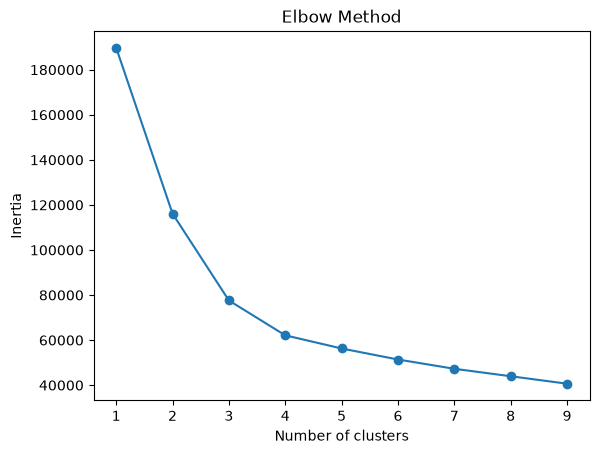

In [631]:
plt.plot(range(1, 10), inertia, marker="o")

plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [632]:
inertia=[]

for k in range(1,6):
    model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=30
    )
    model.fit(X_train_scaled)

    inertia.append(model.inertia_)
print(inertia)

[189773.37730616092, 116143.65950362755, 77586.36613309888, 62126.81575115048, 56284.92379962619]


In [633]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_train_scaled,
    model.labels_,
    sample_size=10000,
    random_state=42
)

print("Silhouette Score:", score)

Silhouette Score: 0.33383424796255085


In [635]:
print(df.columns)
print(df.shape)
print(len(model.labels_))
print(X.columns)

Index(['customer_id', 'age', 'annual_income_inr', 'orders_last_12_months',
       'average_order_value_inr', 'total_spend_last_12_months_inr',
       'days_since_last_purchase', 'days_since_registration',
       'discount_order_percentage', 'preferred_channel', 'clusters'],
      dtype='str')
(74104, 11)
74104
Index(['annual_income_inr', 'orders_last_12_months', 'average_order_value_inr',
       'total_spend_last_12_months_inr', 'discount_order_percentage'],
      dtype='str')


In [ ]:
# from sklearn.cluster import KMeans
# from sklearn.metrics import silhouette_score

# for k in range(2, 11):
#     km = KMeans(n_clusters=k, random_state=42, n_init=50)
#     km.fit(X_train_scaled)

#     score = silhouette_score(
#         X_train_scaled,
#         km.labels_,
#         sample_size=10000,
#         random_state=42
#     )

#     print(k, score)

2 0.3551608891460362
3 0.41935320699741624
4 0.3513762980069959
5 0.33383424796255085
6 0.32133270776515777
7 0.2993985680958575
8 0.2563600654086394
9 0.25544573780122326
10 0.2555288180912859


In [636]:
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(model, f)